In [82]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

1. Bisnis Understanding

## 2. DATA UNDERSTANDING

In [83]:
# Membaca dataset 
data = pd.read_csv('data-ispu-jakarta.csv')
df = data.copy()

print("=" * 55)
print("INFORMASI STRUKTUR DATASET ISPU")
print("=" * 55)

print(f"Jumlah observasi : {df.shape[0]}")
print(f"Jumlah atribut   : {df.shape[1]}")

print("\nDaftar atribut:")
for nomor, kolom in enumerate(df.columns, start=1):
    print(f"{nomor}. {kolom}")

print("\nTipe data masing-masing atribut:")
display(df.dtypes.rename("Tipe Data").to_frame())

INFORMASI STRUKTUR DATASET ISPU
Jumlah observasi : 3501
Jumlah atribut   : 13

Daftar atribut:
1. periode_data
2. bulan
3. tanggal
4. stasiun
5. pm_sepuluh
6. pm_duakomalima
7. sulfur_dioksida
8. karbon_monoksida
9. ozon
10. nitrogen_dioksida
11. max
12. parameter_pencemar_kritis
13. kategori

Tipe data masing-masing atribut:


,Tipe Data
periode_data,int64
bulan,int64
tanggal,int64
stasiun,str
pm_sepuluh,float64
pm_duakomalima,float64
sulfur_dioksida,float64
karbon_monoksida,float64
ozon,float64
nitrogen_dioksida,float64


#### 2.3. Kualitas Data (Missing Value, Duplikasi Data, Outlier)

##### 2.3.1. Missing value

In [84]:
# Mengecek jumlah missing value setiap kolom
missing_count = df.isnull().sum()

# Persentase missing value
missing_percentage = (100 * df.isnull().sum() / len(df)).round(2)

tabel_missing = pd.DataFrame({
    "Jumlah Missing": missing_count,
    "Persentase Missing (%)": missing_percentage
}).sort_values(
    by="Jumlah Missing",
    ascending=False
)

display(tabel_missing)

,Jumlah Missing,Persentase Missing (%)
pm_sepuluh,264,7.54
nitrogen_dioksida,69,1.97
parameter_pencemar_kritis,65,1.86
pm_duakomalima,61,1.74
sulfur_dioksida,56,1.60
karbon_monoksida,50,1.43
ozon,46,1.31
max,8,0.23
kategori,1,0.03
stasiun,0,0.00


##### 2.3.2. DUPLICATE DATA

In [85]:
duplicate_count = df.duplicated().sum()
duplicate_percentage = (duplicate_count / len(df)) * 100

tabel_duplicate = pd.DataFrame({
    'Jumlah Duplikat': [duplicate_count],
    'Persentase (%)': [duplicate_percentage]
})

display(tabel_duplicate)

,Jumlah Duplikat,Persentase (%)
0,0,0.0


##### 2.3.3. IDENTIFIKASI OUTLIER IQR

In [86]:
# Mengidentifikasi kolom yang memiliki tipe data numerik
kolom_numerik_penelitian = df.select_dtypes(
    include='number'
).columns.tolist()

print("Kolom numerik:")
display(kolom_numerik_penelitian)

Kolom numerik:


['periode_data',
 'bulan',
 'tanggal',
 'pm_sepuluh',
 'pm_duakomalima',
 'sulfur_dioksida',
 'karbon_monoksida',
 'ozon',
 'nitrogen_dioksida',
 'max']

In [87]:
# IDENTIFIKASI KANDIDAT OUTLIER DENGAN IQR
hasil_outlier = []

for kolom in kolom_numerik_penelitian:

    nilai = df[kolom].dropna()

    if len(nilai) == 0:
        continue

    Q1 = nilai.quantile(0.25)
    Q3 = nilai.quantile(0.75)
    IQR = Q3 - Q1

    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR

    kandidat = (
        (nilai < batas_bawah) |
        (nilai > batas_atas)
    )

    hasil_outlier.append({
        "Atribut": kolom,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Batas Bawah": batas_bawah,
        "Batas Atas": batas_atas,
        "Jumlah Kandidat": int(kandidat.sum()),
        "Persentase (%)": round(
            kandidat.mean() * 100, 2
        )
    })

tabel_outlier = pd.DataFrame(hasil_outlier)

print("Hasil identifikasi kandidat outlier:")
display(tabel_outlier)

Hasil identifikasi kandidat outlier:


,Atribut,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Kandidat,Persentase (%)
0,periode_data,202406.0,202506.0,100.0,202256.0,202656.0,0,0.00
1,bulan,3.0,9.0,6.0,-6.0,18.0,0,0.00
2,tanggal,8.0,23.0,15.0,-14.5,45.5,0,0.00
3,pm_sepuluh,37.0,60.0,23.0,2.5,94.5,9,0.28
4,pm_duakomalima,56.0,87.0,31.0,9.5,133.5,9,0.26
5,sulfur_dioksida,24.0,53.0,29.0,-19.5,96.5,1,0.03
6,karbon_monoksida,10.0,20.0,10.0,-5.0,35.0,20,0.58
7,ozon,15.0,29.0,14.0,-6.0,50.0,169,4.89
8,nitrogen_dioksida,15.0,37.0,22.0,-18.0,70.0,60,1.75
9,max,58.0,87.0,29.0,14.5,130.5,33,0.94


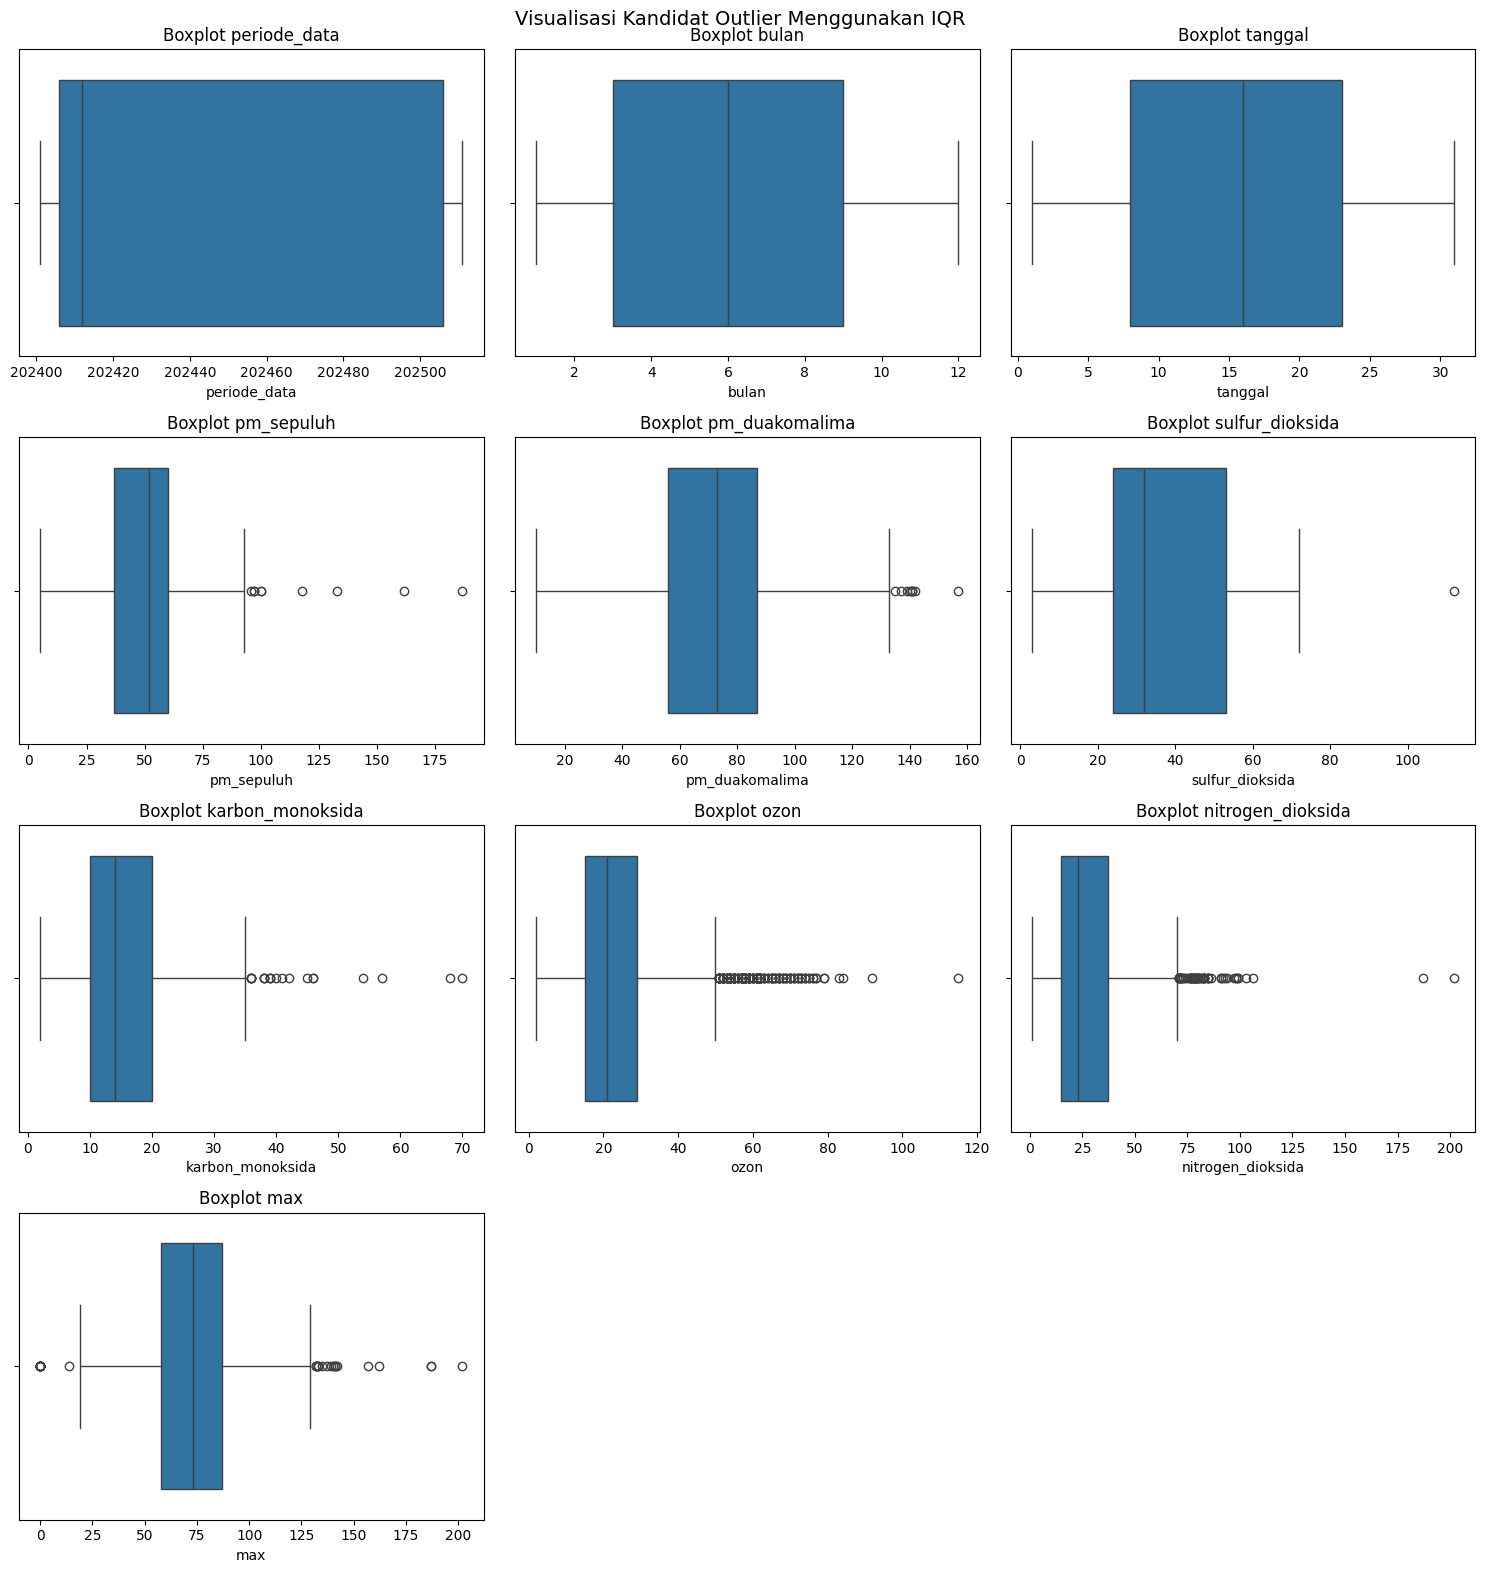

In [88]:
if kolom_numerik_penelitian:

    jumlah_kolom = len(kolom_numerik_penelitian)
    jumlah_baris = (jumlah_kolom + 2) // 3

    fig, axes = plt.subplots(
        jumlah_baris, 3,
        figsize=(15, 4 * jumlah_baris)
    )

    axes = axes.flatten() if jumlah_kolom > 1 else [axes]

    for i, kolom in enumerate(kolom_numerik_penelitian):
        sns.boxplot(
            x=df[kolom].dropna(),
            ax=axes[i]
        )

        axes[i].set_title(
            f'Boxplot {kolom}'
        )
        axes[i].set_xlabel(kolom)

    # Menghapus subplot yang tidak terpakai
    for i in range(jumlah_kolom, len(axes)):
        fig.delaxes(axes[i])

    plt.suptitle(
        'Visualisasi Kandidat Outlier Menggunakan IQR',
        fontsize=14
    )
    plt.tight_layout()
    plt.show()

##### 2.3.4. Konsistensi Data

In [89]:
# Cek tipe data dan struktur kolom

print("Tipe data setiap kolom:")
display(pd.DataFrame({
    "Tipe Data": df.dtypes.astype(str),
}))

Tipe data setiap kolom:


,Tipe Data
periode_data,int64
bulan,int64
tanggal,int64
stasiun,str
pm_sepuluh,float64
pm_duakomalima,float64
sulfur_dioksida,float64
karbon_monoksida,float64
ozon,float64
nitrogen_dioksida,float64


In [90]:
#  Cek konsistensi kategori
kolom_kategori = df.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

for kolom in kolom_kategori:
    print(f"\nNilai unik pada kolom '{kolom}':")
    display(df[kolom].value_counts(dropna=False))


Nilai unik pada kolom 'stasiun':


stasiun
DKI3 JAGAKARSA                        700
DKI2 KELAPA GADING                    700
DKI4 LUBANG BUAYA                     700
DKI1 BUNDARAN HOTEL INDONESIA (HI)    579
DKI5 KEBON JERUK                      551
DKI5 KEBON JERUK JAKARTA BARAT        150
DKI1 BUNDERAN HI                       90
DKI1 BUNDARAN HOTEL INDONESIA HI       31
Name: count, dtype: int64


Nilai unik pada kolom 'parameter_pencemar_kritis':


parameter_pencemar_kritis
PM25    2955
SO2      225
PM10     176
NaN       65
O3        52
NO2       27
CO         1
Name: count, dtype: int64


Nilai unik pada kolom 'kategori':


kategori
SEDANG                2694
BAIK                   444
TIDAK SEHAT            341
TIDAK ADA DATA          20
SANGAT TIDAK SEHAT       1
NaN                      1
Name: count, dtype: int64

In [91]:
kolom_numerik_penelitian = df.select_dtypes(
    include="number"
).columns.tolist()

print("Statistik kolom numerik:")
display(df[kolom_numerik_penelitian].describe().T)

Statistik kolom numerik:


,count,mean,std,min,25%,50%,75%,max
periode_data,3501.0,202454.007141,49.819115,202401.0,202406.0,202412.0,202506.0,202511.0
bulan,3501.0,6.277921,3.322589,1.0,3.0,6.0,9.0,12.0
tanggal,3501.0,15.731505,8.801260,1.0,8.0,16.0,23.0,31.0
pm_sepuluh,3237.0,48.884461,16.549760,5.0,37.0,52.0,60.0,187.0
pm_duakomalima,3440.0,71.402907,23.210540,10.0,56.0,73.0,87.0,157.0
sulfur_dioksida,3445.0,36.031350,15.878683,3.0,24.0,32.0,53.0,112.0
karbon_monoksida,3451.0,15.099681,6.826753,2.0,10.0,14.0,20.0,70.0
ozon,3455.0,23.786975,12.801604,2.0,15.0,21.0,29.0,115.0
nitrogen_dioksida,3432.0,27.206002,16.665791,1.0,15.0,23.0,37.0,202.0
max,3493.0,73.089035,21.413331,0.0,58.0,73.0,87.0,202.0


#### 2.4. Exploratory Data Analysis

##### 2.4.1 Korelasi Antar Parameter Kualitas Udara

Matriks korelasi antarfitur numerik:


,pm_sepuluh,pm_duakomalima,sulfur_dioksida,karbon_monoksida,ozon,nitrogen_dioksida,max
pm_sepuluh,1.00,0.70,0.15,0.40,0.13,0.16,0.71
pm_duakomalima,0.70,1.00,0.08,0.35,0.32,0.22,0.94
sulfur_dioksida,0.15,0.08,1.00,-0.20,-0.08,0.24,0.15
karbon_monoksida,0.40,0.35,-0.20,1.00,0.17,0.12,0.34
ozon,0.13,0.32,-0.08,0.17,1.00,-0.12,0.31
nitrogen_dioksida,0.16,0.22,0.24,0.12,-0.12,1.00,0.28
max,0.71,0.94,0.15,0.34,0.31,0.28,1.00


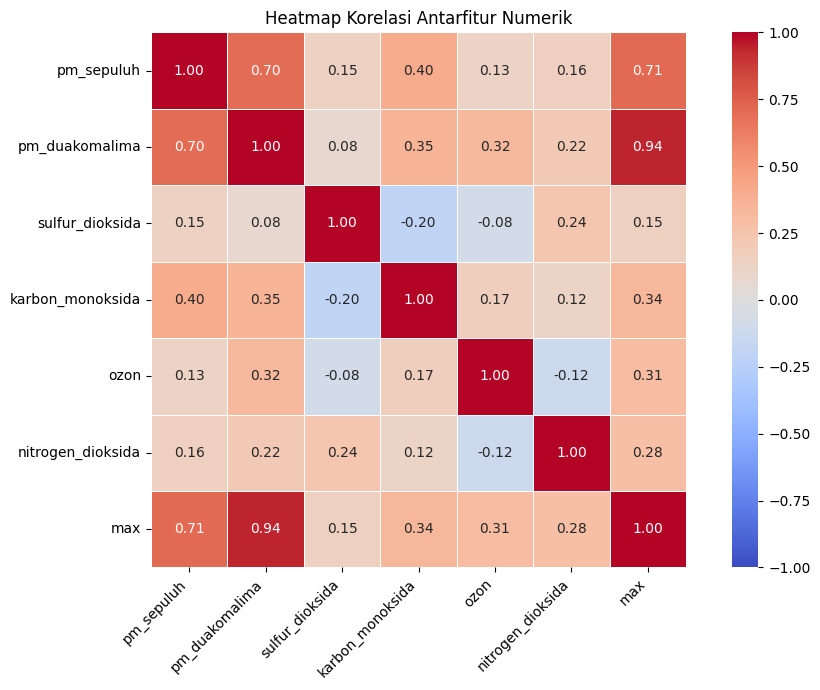

In [92]:
# Parameter numerik kualitas udara

# Mengecualikan kolom waktu dan identitas
kata_waktu_id = {
    "tanggal", "date", "bulan", "month",
    "tahun", "year", "hari", "day",
    "periode", "id", "no"
}

kolom_korelasi = [
    kolom for kolom in kolom_numerik_penelitian
    if not any(
        kata in kata_waktu_id
        for kata in kolom.lower().replace("-", "_").split("_")
    )
]

# Menghitung korelasi Pearson
data_korelasi = df[kolom_korelasi]
matriks_korelasi = data_korelasi.corr(method="pearson")

print("Matriks korelasi antarfitur numerik:")
display(matriks_korelasi.round(2))

# Visualisasi heatmap
plt.figure(
    figsize=(
        max(10, len(kolom_korelasi) * 1.2),
        max(7, len(kolom_korelasi) * 0.9)
    )
)

sns.heatmap(
    matriks_korelasi,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5
)

plt.title("Heatmap Korelasi Antarfitur Numerik")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

##### 2.4.2 Analisis Distribusi Nilai ISPU

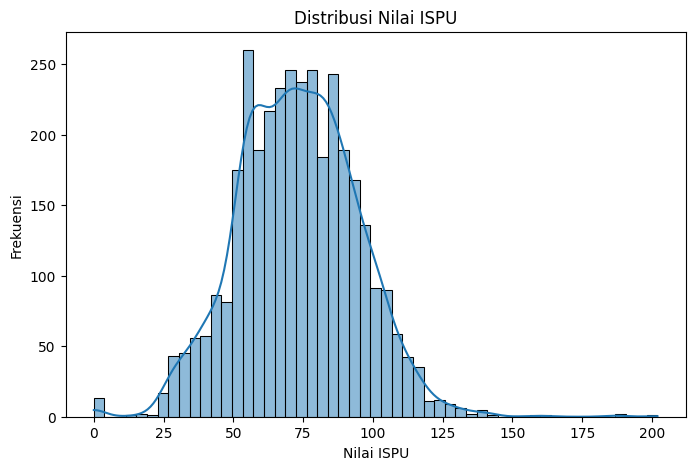

In [93]:
# Melihat distribusi nilai ISPU
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="max", kde=True)
plt.title("Distribusi Nilai ISPU")
plt.xlabel("Nilai ISPU")
plt.ylabel("Frekuensi")
plt.show()

##### 2.4.3 Analisis Rata-rata Parameter Pencemar

                   Rata-rata  Jumlah Data Valid
pm_sepuluh             48.88               3237
pm_duakomalima         71.40               3440
sulfur_dioksida        36.03               3445
karbon_monoksida       15.10               3451
ozon                   23.79               3455
nitrogen_dioksida      27.21               3432


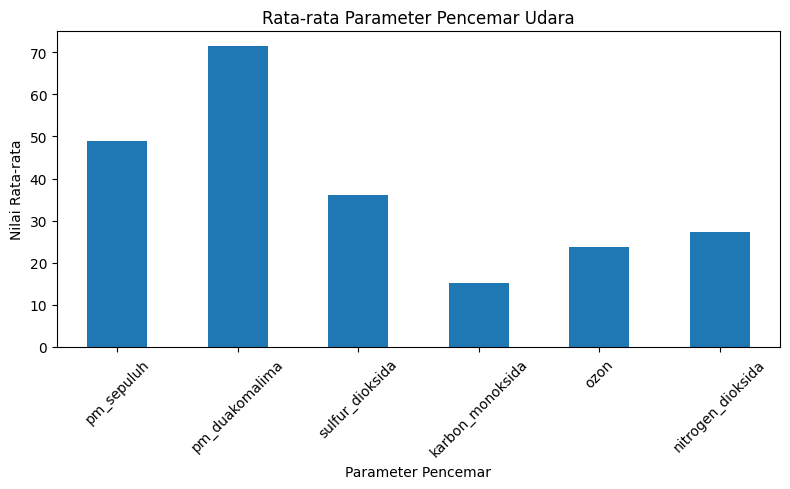

In [94]:
parameter = [
    'pm_sepuluh',
    'pm_duakomalima',
    'sulfur_dioksida',
    'karbon_monoksida',
    'ozon',
    'nitrogen_dioksida'
]

parameter_ada = [
    kolom for kolom in parameter
    if kolom in df.columns
]

if parameter_ada:
    # Menghitung rata-rata dan jumlah data valid
    ringkasan = pd.DataFrame({
        'Rata-rata': df[parameter_ada].mean(),
        'Jumlah Data Valid': df[parameter_ada].count()
    })

    print(ringkasan.round(2))

    # Visualisasi rata-rata
    ringkasan['Rata-rata'].plot(
        kind='bar',
        figsize=(8, 5)
    )

    plt.title('Rata-rata Parameter Pencemar Udara')
    plt.xlabel('Parameter Pencemar')
    plt.ylabel('Nilai Rata-rata')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
else:
    print("Kolom parameter pencemar belum ditemukan.")

2.4.4 Analisis Distribusi Kategori Kualitas Udara


,Jumlah,Persentase (%)
kategori,,
BAIK,444,12.69
SEDANG,2694,76.97
TIDAK SEHAT,341,9.74
SANGAT TIDAK SEHAT,1,0.03
TIDAK ADA DATA,20,0.57


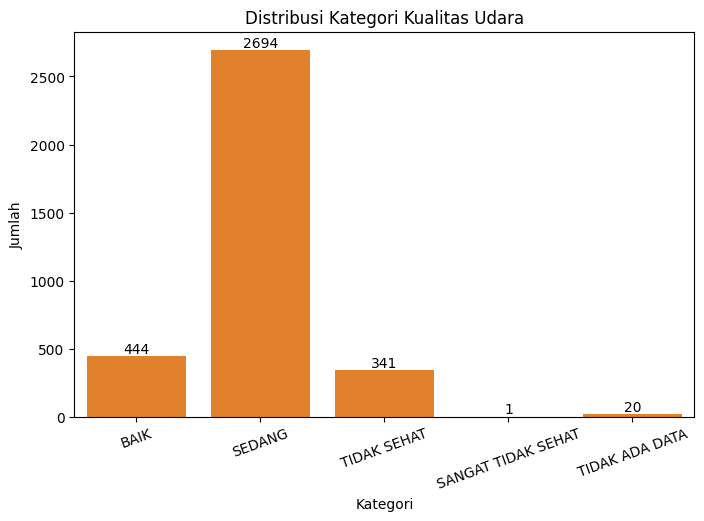

In [95]:
# Jumlah dan persentase setiap kategori
urutan = ["BAIK", "SEDANG", "TIDAK SEHAT", "SANGAT TIDAK SEHAT", "TIDAK ADA DATA"]

jumlah = df["kategori"].value_counts().reindex(urutan)
persen = (jumlah / jumlah.sum() * 100).round(2)

display(pd.DataFrame({"Jumlah": jumlah, "Persentase (%)": persen}))

# Visualisasi
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="kategori", order=urutan)
ax = sns.countplot(data=df, x="kategori", order=urutan)
ax.bar_label(ax.containers[0])
plt.title("Distribusi Kategori Kualitas Udara")
plt.xlabel("Kategori")
plt.ylabel("Jumlah")
plt.xticks(rotation=20)
plt.show()

2.4.5 Analisis Kualitas Udara Berdasarkan Stasiun Pemantauan

,mean,median,max
stasiun_bersih,,,
DKI1 BUNDARAN HOTEL INDONESIA (HI),73.0,74.0,120.0
DKI2 KELAPA GADING,73.9,74.0,132.0
DKI3 JAGAKARSA,72.4,70.0,202.0
DKI4 LUBANG BUAYA,70.8,69.0,187.0
DKI5 KEBON JERUK,76.6,78.0,157.0


kategori,BAIK,SANGAT TIDAK SEHAT,SEDANG,TIDAK SEHAT
stasiun_bersih,,,,
DKI1 BUNDARAN HOTEL INDONESIA (HI),15.31,0.00,78.25,6.44
DKI2 KELAPA GADING,11.48,0.00,78.62,9.90
DKI3 JAGAKARSA,4.89,0.14,90.23,4.74
DKI4 LUBANG BUAYA,16.09,0.00,72.32,11.59
DKI5 KEBON JERUK,16.05,0.00,67.62,16.33


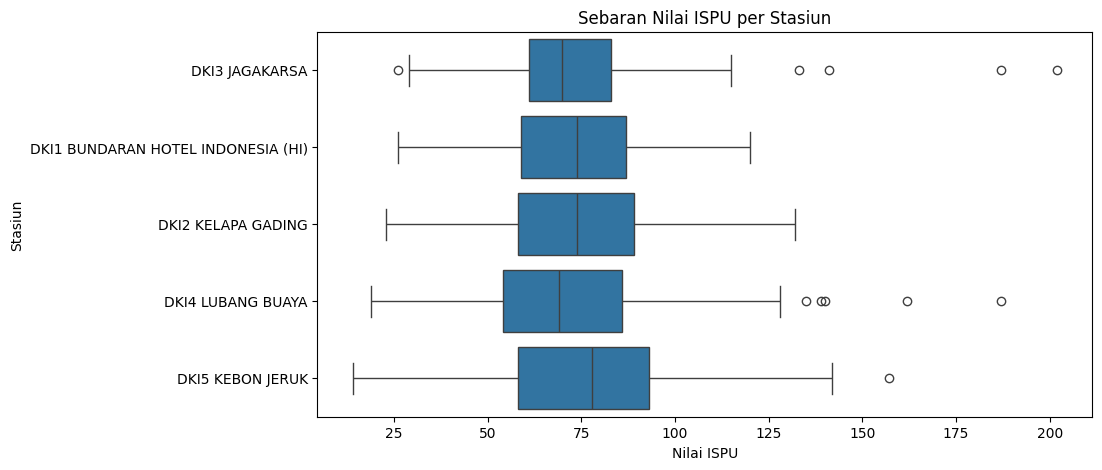

In [96]:
# Menyatukan penulisan nama stasiun yang berbeda
df["stasiun_bersih"] = df["stasiun"].replace({
    "DKI1 BUNDERAN HI": "DKI1 BUNDARAN HOTEL INDONESIA (HI)",
    "DKI1 BUNDARAN HOTEL INDONESIA HI": "DKI1 BUNDARAN HOTEL INDONESIA (HI)",
    "DKI5 KEBON JERUK JAKARTA BARAT": "DKI5 KEBON JERUK"
})

df_stasiun = df[df["max"] > 0]

# Rata-rata, median, dan nilai maksimum ISPU per stasiun
display(df_stasiun.groupby("stasiun_bersih")["max"].agg(["mean", "median", "max"]).round(1))

# Persentase kategori per stasiun
display((pd.crosstab(df_stasiun["stasiun_bersih"], df_stasiun["kategori"], normalize="index") * 100).round(2))

# Visualisasi sebaran ISPU per stasiun
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_stasiun, y="stasiun_bersih", x="max")
plt.title("Sebaran Nilai ISPU per Stasiun")
plt.xlabel("Nilai ISPU")
plt.ylabel("Stasiun")
plt.show()

2.4.6 Analisis Tren Kualitas Udara Bulanan

bulan
1     55.0
2     61.6
3     59.1
4     69.4
5     85.0
6     90.2
7     85.0
8     85.3
9     80.8
10    77.5
11    63.0
12    56.5
Name: max, dtype: float64

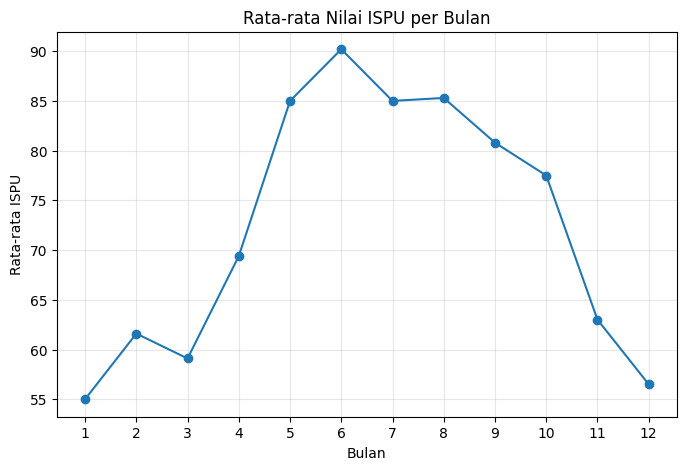

In [97]:
# Rata-rata ISPU setiap bulan
rata_bulan = df.groupby("bulan")["max"].mean().round(1)
display(rata_bulan)

# Visualisasi tren bulanan
plt.figure(figsize=(8, 5))
plt.plot(rata_bulan.index, rata_bulan.values, marker="o")
plt.title("Rata-rata Nilai ISPU per Bulan")
plt.xlabel("Bulan")
plt.ylabel("Rata-rata ISPU")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()